# Definitions

In [1]:
import numpy as np
import scipy as sp
import scipy.linalg as spla
import math
from math import pi, sin, cos, log10
import plotly.graph_objects as go

# ---------------------------------------------------------------------------------------------------------------------------------
# Basic definitions

# Pauli matrices
PAULIS = np.array([
    [[1.0, 0.0], [0.0, 1.0]],
    [[0.0, 1.0], [1.0, 0.0]],
    [[0.0, -1j], [1j, 0.0]],
    [[1.0, 0.0], [0.0, -1.0]]
], dtype=complex)


# Reference sqrt(X) Pauli transfer matrix
T_sqrtX = np.array([
    [1,0,0,0],
    [0,1,0,0],
    [0,0,0,-1],
    [0,0,1,0]
], dtype=np.float64)


# ---------------------------------------------------------------------------------------------------------------------------------
# General utility functions

def nines(x: float) -> float:
    """
    Calculates the number of nines in x
    """
    if x is None or not math.isfinite(x):
        return float('nan')
    if x > 1:
        return float('inf')
    return -log10(1 - x)


def get_ptm(Ks: list[np.ndarray]) -> np.ndarray:
    """
    Computes the Pauli transfer matrix given a list of Kraus operators.
    
    Args:
        Ks: List of 2x2 Kraus operators.
    
    Returns:
        The 4x4 Pauli transfer ndarray
    """
    Ks_arr = np.asarray(Ks, dtype=np.complex128)
    if Ks_arr.ndim == 2:
        Ks_arr = Ks_arr[np.newaxis, :, :]
    return 0.5 * np.real(
        np.einsum('ida,jbc,kab,kdc->ij', PAULIS, PAULIS, Ks_arr, Ks_arr.conj())
    )

def canonical_Schur_decomposition(L: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """
    Obtains the canonical real Schur decomposition for the traceless part (L) of Pauli Transfer Matrix.
    The canonical form places the single real eigenvalue block at the top-left.
    In practice we are only using S here, but we return the gauge unitary V as well.
    Note: We will generally assume the matrix has one real eigenvalue and a complex conjugate pair.
    Adding extra checks here would be redundant.

    Args:
        L: A 3x3 real matrix corresponding to the traceless block of the Pauli Transfer Matrix of a channel.

    Returns:
        (S, V), where S is the canonical Schur form, and V is the Schur decomposition unitary
    """
    if L.shape != (3, 3):
        raise ValueError("Canonical Schur decomposition attempted for a non 3x3 matrix.")
    
    S, V, _ = spla.schur(L, output='real', sort=lambda x,y: np.abs(y) <= 1e-12) # some arbitrary small tolerance
    
    if S[1,2] < 0 and S[2,1] >= 0:
        return S, V

    # Improper ordering for the gauge. Fix it.
    W = np.array([[1,0,0], [0,0,1], [0,1,0]])
    S = W @ S @ W.T
    V = V @ W
        
    return S, V

def canonical_Schur_PTM(T: np.ndarray) -> np.ndarray:
    """
    Gets the canonical Schur form for the a given PTM.

    Args:
        T: The input PTM

    Returns:
        The canonical Schur form of T
    """
    S, V = canonical_Schur_decomposition(T[1:,1:])

    if abs(S[1,1] - S[2,2]) > 1e-12:
        raise ValueError("The channel's transfer matrix only has real eigenvalues.")

    # Construct global unitary transformation for the PTM
    U = spla.block_diag([[1]], V)
    
    # Convert entire T into the Schur gauge
    SchurT = U.conj().T @ T @ U

    return SchurT

# ---------------------------------------------------------------------------------------------------------------------------------
# Protocol construction

def get_Schur_gauge_state(alpha: float = 0.0, beta: float = 0.0, gamma: float = 0.0) -> np.ndarray:
    """
    Constructs a PTM state in spherical coordinates, assumed to be in the Schur gauge.

    Args:
        alpha: polar angle
        beta: azimuthal angle
        gamma: depolarization
    
    Returns:
        The PTM initial state.
    """
    r = 1.0 - gamma
    return (1.0 / np.sqrt(2.0)) * np.array([
        1.0,
        r * np.sin(alpha) * np.cos(beta),
        r * np.sin(alpha) * np.sin(beta),
        r * np.cos(alpha)
    ])


def readout_error(p01: float, p10: float) -> np.ndarray:
    """Classical readout error matrix in the Pauli Transfer Matrix representation.
    
    Args:
        p01: Probability of measuring |0> given state |1>
        p10: Probability of measuring |1> given state |0>.
    
    Returns:
        The PTM which, acting on the right of a measurement, produces the appropriate readout error.
    """
    return np.array([
        [1.0, 0.0, 0.0, 0.0],
        [0.0, 0.0, 0.0, 0.0],
        [0.0, 0.0, 0.0, 0.0],
        [p10 - p01, 0.0, 0.0, 1.0 - p01 - p10]
    ])


def get_Schur_gauge_measurement(p01: float = 0.0, p10: float = 0.0) -> np.ndarray:
    """
    Shorthand for imperfect measurements with readout error.
    """
    return (1.0 / np.sqrt(2.0)) * np.array([1, 0, 0, 1]) @ readout_error(p01, p10)


def noise_depolarizing(t: float) -> np.ndarray:
    """
    PTM of the depolarization channel with parameter 0 <= t <= 1.
    """
    if t < 0 or t > 1:
        raise ValueError("Noise parameter not in range [0,1].")
    return np.diag([1.0, 1.0 - t, 1.0 - t, 1.0 - t])


def noise_dephasing(t: float) -> np.ndarray:
    """
    PTM of the (Schur) z-basis dephasing channel with parameter 0 <= t <= 1.
    """
    if t < 0 or t > 1:
        raise ValueError("Noise parameter not in range [0,1].")
    return np.diag([1.0, 1.0 - t, 1.0 - t, 1.0])


def noise_amplitude_damping(t: float) -> np.ndarray:
    """
    PTM of the (Schur) z-basis amplitude damping channel with parameter 0 <= t <= 1.
    """
    val = np.sqrt(1.0 - t)
    return np.array([
        [1.0, 0.0, 0.0, 0.0],
        [0.0, val, 0.0, 0.0],
        [0.0, 0.0, val, 0.0],
        [t, 0.0, 0.0, 1.0 - t]
    ])


def noise_overrotation(delta_phi: float) -> np.ndarray:
    """
    PTM of the (Schur) x-axis over-rotation channel.
    Actually, just a rotation around x, but we use it as over-rotation.
    """
    c = cos(delta_phi)
    s = sin(delta_phi)
    return np.array([
        [1, 0, 0, 0],
        [0, 1, 0, 0],
        [0, 0, c, -s],
        [0, 0, s, c]
    ])

# ---------------------------------------------------------------------------------------------------------------------------------
# Fidelity computation

def get_exact_Schur_gauge_fidelity(T: np.ndarray) -> float:
    """
    Computes the exact average gate fidelity F_avg in the Schur gauge.

    Args:
        T: Pauli Transfer Matrix of the channel.

    Returns:
        Exact average gate fidelity in the Schur gauge.
    """
    S, _ = canonical_Schur_decomposition(T[1:,1:])
    return 1/2 + (S[0,0] + abs(S[1,2]) + abs(S[2,1]))/6


def get_fidelity_lower_bound(lambda1_abs: float, lambda1_phase: float) -> float:
    """
    Returns lower bound from lambda1's magnitude and phase offset from pi/2
    """
    return 1/3 + lambda1_abs*(1 + math.sin(lambda1_phase))/3


def get_epsilon(T: np.ndarray, state: np.ndarray, measurement: np.ndarray, n: int) -> float:
    """
    Computes epsilon_n
    """
    if n % 2 != 0:
        raise ValueError(f"Parameter n must be even, got {n}.")
    Tn = np.linalg.matrix_power(T, n) # Minor optimization, compute this bit only once
    # Compute in complexes just to be safe
    return (
        1 - ([1,-1][(n//2) % 2]) * (measurement @ (Tn - Tn @ T @ T) @ state)
    ).real


def get_xi(T: np.ndarray, state: np.ndarray, measurement: np.ndarray, j: int = 1, i: int = 0) -> float | None:
    """
    Computes xi
    """
    eps = list(sorted([
        get_epsilon(T, state, measurement, k*j + i) for k in [0, 2, 4, 6] # explicitly, for clarity
    ]))
    ratio = (eps[3] + eps[2] - eps[1] - eps[0]) / (1 - eps[1])
    if ratio < 0:
        return None
    return math.sqrt(ratio)


def get_simulated_SPAM_bound(
    SchurT: np.ndarray,
    state: np.ndarray,
    measurement: np.ndarray,
    j: int,
    ell: int,
    i: int = 0
) -> float | None:
    """
    Calculates the fidelity lower bound with SPAM errors
    
    Args:
        SchurT: Pauli Transfer Matrix of the channel in the Schur gauge.
        state: PTM of the state preparation in the Schur gauge.
        measurement: PTM of the measurement in the Schur gauge.
        j: Sequence length spacing for samples.
        ell: Reference long-range sequence length.
        i: Optional offset.
    
    Returns:
        float: Computed simulated lower bound.
    """
    if j % 2 == 0:
        raise ValueError(f"Parameter j must be odd, got {j}.")
    if ell % 2 == 1:
        raise ValueError(f"Parameter ell must be even, got {ell}.")
    if ell < 22:
        raise ValueError(f"Parameter ell must be at least 22, got {ell}.")
    if i % 2 == 1:
        raise ValueError(f"Parameter i must be even, got {i}.")
    
    if abs(SchurT[3,2]) < 1e-12:
        raise ValueError("The channel's transfer matrix only has real eigenvalues.")
    
    xi = get_xi(SchurT, state, measurement, j, i)
    
    if xi is None or xi < 0 or xi > 1:
        return None
    
    cond1 = math.sqrt(get_epsilon(SchurT, state, measurement, i)) + math.sqrt(get_epsilon(SchurT, state, measurement, i+2)) <= 1/2
    cond2 = abs(1 - get_epsilon(SchurT, state, measurement, ell)) >= 0.7
    
    if not cond1:
        return None
    if not cond2:
        return None
    
    est_lambda1_abs = abs(get_epsilon(SchurT, state, measurement, ell) - 1) ** (1.0 / (max(22, ell) - 11))
    est_phi = math.asin(xi) / (2 * j)
    
    return get_fidelity_lower_bound(est_lambda1_abs, math.pi/2 + est_phi)


# ---------------------------------------------------------------------------------------------------------------------------------
# Plot and visualization

def plot_SPAM_curves(
    data: dict[tuple[int, int], tuple[np.ndarray, list[float | None]]],
    Favg_exact: float,
) -> None:
    fig = go.Figure()

    for jl, curve in data.items():
        j, ell = jl
        if j % 2 == 0:
            raise ValueError(f"Parameter j must be odd, got {j}.")
        if ell % 2 != 0:
            raise ValueError(f"Parameter ell must be even, got {ell}.")
        fig.add_trace(go.Scatter(
            x=curve[0], y=curve[1],
            mode="lines", name=f"j={j}, ℓ={ell}"
        ))
    
    fig.add_hline(
        y=nines(Favg_exact),
        line_dash="dash", line_color="black", line_width=1.5,
        annotation_text=f"Exact Favg = {Favg_exact:0.7f} / {nines(Favg_exact):0.04f} nines",
        annotation_position="top right"
    )
    
    axis_style = dict(
        showgrid=True, gridcolor="#dddddd",
        gridwidth=1, showline=True,
        linecolor="black", linewidth=1,
        mirror=True, ticks="inside"
    )
    
    fig.update_layout(
        template="plotly_white", paper_bgcolor="white", plot_bgcolor="white",
        xaxis=dict(
            range=[0.0, 1.0], minallowed=0.0, maxallowed=1.0,
            title="t", **axis_style,
        ),
        yaxis=dict(
            rangemode="nonnegative", title="Fidelity (nines)",
            minallowed=0.0, **axis_style,
        ),
        width=600,
        height=300,
        legend=dict(x=1.02, y=1, xanchor="left", yanchor="top"),
        margin=dict(l=40, r=40, t=40, b=40)
    )
    fig.show()

def plot_epsilon_signal(
    SchurT: np.ndarray,
    SPAM_cases: list[tuple[str, np.ndarray, np.ndarray]],
    n_max: int = 1000,
    samples: dict[str, int] | None = None,
) -> None:
    if samples is not None:
        j = samples.get("j", 1)
        ell = samples.get("ell", 22)
        i = samples.get("i", 0)
        if j % 2 == 0:
            raise ValueError(f"Parameter j must be odd, got {j}.")
        if ell % 2 != 0:
            raise ValueError(f"Parameter ell must be even, got {ell}.")
        if i % 2 != 0:
            raise ValueError(f"Parameter i must be even, got {i}.")
    
    def signal(state, measurement):
        return list(zip(*[
            (n, get_epsilon(SchurT, state, measurement, n))
            for n in range(0, n_max+1, 2)
        ]))

    signals = [
        (k, signal(state, measurement))
        for k, state, measurement in SPAM_cases
    ]

    if samples is not None:
        dots = [i, 2*j+i, 4*j+i, 6*j+i, ell]
        dot_y = [
            (k, [get_epsilon(SchurT, state, measurement, n) for n in dots])
            for k, state, measurement in SPAM_cases
        ]
    
    fig = go.Figure()
    
    for k, (x, y) in signals:
        fig.add_trace(go.Scatter(
            x=x, y=y, mode="lines",
            name=f"{k} signal"
        ))

    if samples is not None:
        for k, y in dot_y:
            fig.add_trace(go.Scatter(
                x=dots, y=y, mode="markers",
                marker=dict(color="black", size=3),
                name=f"{k} samples", showlegend=True
            ))
    
    axis_style = dict(
        showgrid=True, gridcolor="#ddd", gridwidth=1,
        showline=True, linecolor="black", linewidth=1,
        mirror=True, ticks="inside"
    )

    if samples is not None:
        print(f"Samples for j={j}, ℓ={ell}, i={i}")
    
    fig.update_layout(
        template="plotly_white", paper_bgcolor="white", plot_bgcolor="white",
        width=580, height=300,
        margin=dict(l=40, r=40, t=40, b=40),
        xaxis=dict(
            range=[0, n_max], minallowed=0, maxallowed=n_max,
            title="n", **axis_style
        ),
        yaxis=dict(
            range=[0, 2], minallowed=0, maxallowed=2,
            tickmode="array", tickvals=[0, 0.3, 1.0, 1.7, 2.0],
            title="ε<sub>n</sub>", **axis_style
        ),
        legend=dict(x=1.02, y=1, xanchor="left", yanchor="top")
    )
    
    fig.show()

def run_scenario(
    T: np.ndarray,
    state_model,
    measurement_model,
    jl_curves: list[tuple[int, int]],
    n_max: int,
    samples_jl: tuple[int, int],
    i: int = 0,
) -> None:
    """
    Runs a noisy scenario on a parametric SPAM model, and plots the corresponding epsilon_n signal curves.

    Args:
        T: PTM of the channel
        state_model: a callable function state(t) returning the state for a parameter t in [0,1]
        measurement_model: a callable function meas(t) returning the state for a parameter t in [0,1]
        jl_curves: a list of tuples (j, ell), specifying which curves to plot
        n_max: maximum sequence length for the signal plot
        samples_jl: in the signal plot, which (j, ell) to mark as the measured samples
        i: sample length offset
    """
    Favg_exact = get_exact_Schur_gauge_fidelity(T)
    SchurT = canonical_Schur_PTM(T)
    print(f"Exact F_avg in Schur gauge: {Favg_exact:0.10f} = {nines(Favg_exact):0.04f} nines")
    
    num_points = 200
    
    t_values = np.linspace(0, 1.0, num_points)
    
    states = [ state_model(t) for t in t_values ]
    measurements = [ measurement_model(t) for t in t_values ]
    data = {
        jl: (
            t_values,
            [
                nines(get_simulated_SPAM_bound(SchurT, state, measurement, j, ell, i))
                for t, state, measurement in zip(t_values, states, measurements)
            ]
        )
        for jl in jl_curves
        for j, ell in [jl]
    }
    
    plot_SPAM_curves(data, Favg_exact)
    
    j, ell = samples_jl
    plot_epsilon_signal(
        SchurT,
        [
            ("t=0", states[ 0], measurements[ 0]),
            ("t=1", states[-1], measurements[-1])
        ],
        n_max,
        {"j": j, "ell": ell, "i": i}
    )

---
# Simulations

Below we analyze the performance of our method in a variety of noisy scenarios featuring SPAM errors. Generally, the ideal choices of $\ell$ occur when $|1 - \varepsilon_\ell|$ is a local maximum satisfying $|1 - \varepsilon_\ell| \ge 7/10$. The optimal choice of $j$ is largely dependent on the specific noise model. In this notebook, we do not include the choices of offset $i$, save for a specific scenario later.

### Dephasing noise and readout error

In this scenario, the optimal $\ell$ is generally the largest such that $|1 - \varepsilon_\ell| \ge 0.7$. The bound is generally tighter for larger $j$ as well. The downward slope is mostly due to the increase in readout error.

Dephasing: 0.0007
Exact F_avg in Schur gauge: 0.9997666667 = 3.6320 nines


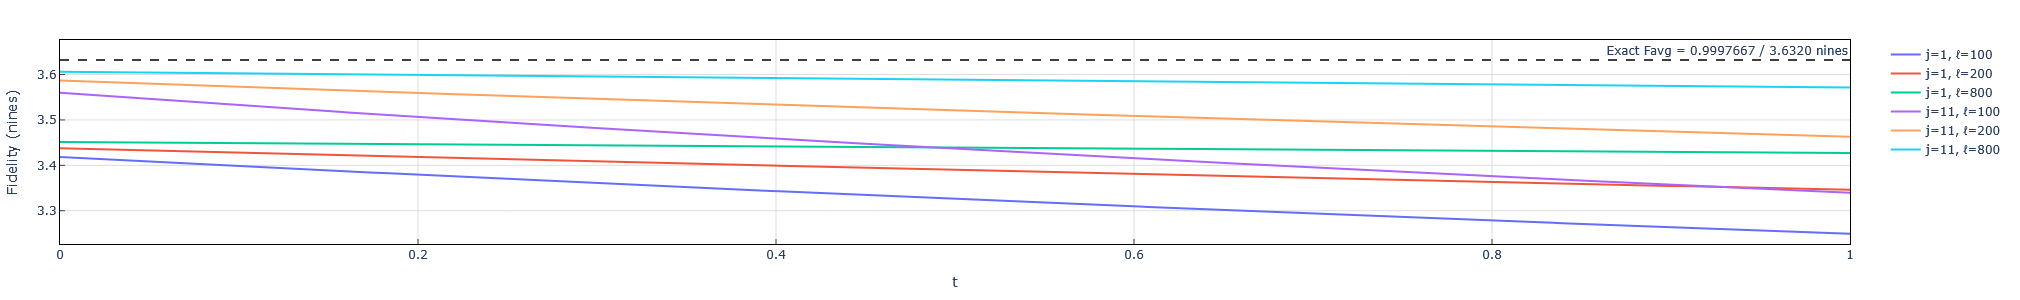

Samples for j=11, ℓ=800, i=0


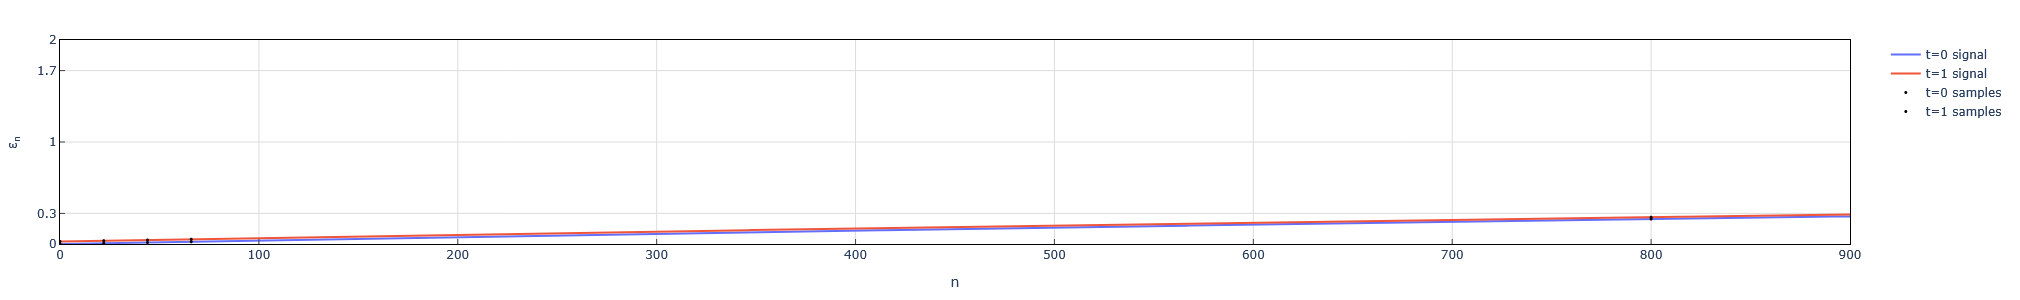

Dephasing: 0.0003
Exact F_avg in Schur gauge: 0.9999000000 = 4.0000 nines


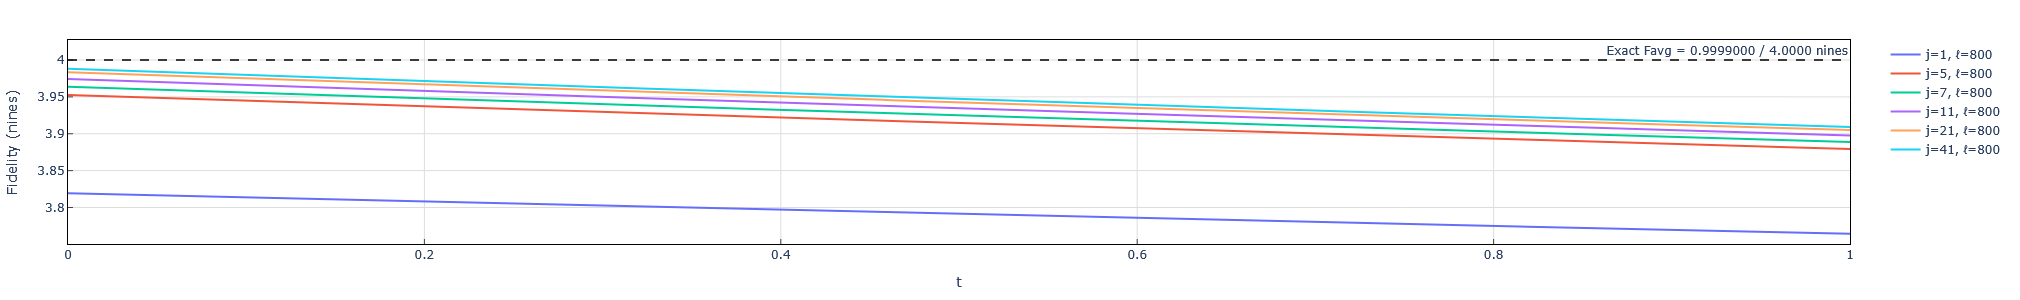

Samples for j=41, ℓ=800, i=0


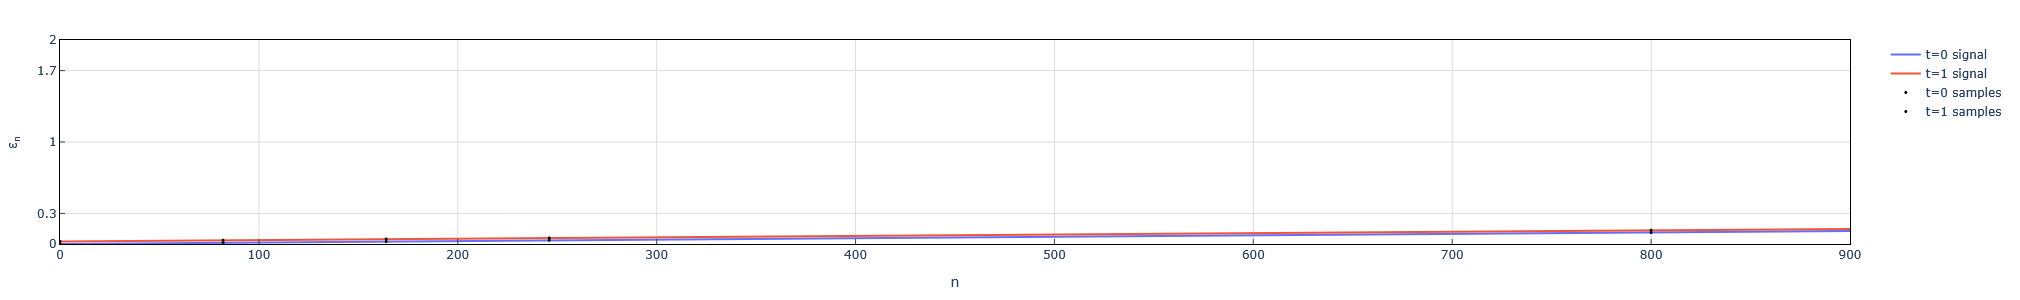

In [2]:
print("Dephasing: 0.0007")
run_scenario(
    noise_dephasing(0.0007) @ T_sqrtX,
    lambda t: get_Schur_gauge_state(),
    lambda t: get_Schur_gauge_measurement(0.01 * t, 0.014 * t),
    [(1, 100), (1, 200), (1, 800), (11, 100), (11, 200), (11, 800)],
    900, (11, 800)
)

print("Dephasing: 0.0003")
run_scenario(
    noise_dephasing(0.0003) @ T_sqrtX,
    lambda t: get_Schur_gauge_state(),
    lambda t: get_Schur_gauge_measurement(0.01 * t, 0.014 * t),
    [(1, 800), (5, 800), (7, 800), (11, 800), (21, 800), (41, 800)],
    900, (41, 800)
)

### Dephasing and overrotation

Under coherent overrotation and dephasing noise, the $\varepsilon_n$ signal features a decaying oscillation. The general rule for choosing $\ell$ applies, but the ideal choice of $j$ is largely dependent on the specifics of the channel and SPAM error.

Exact F_avg in Schur gauge: 0.9998426718 = 3.8032 nines


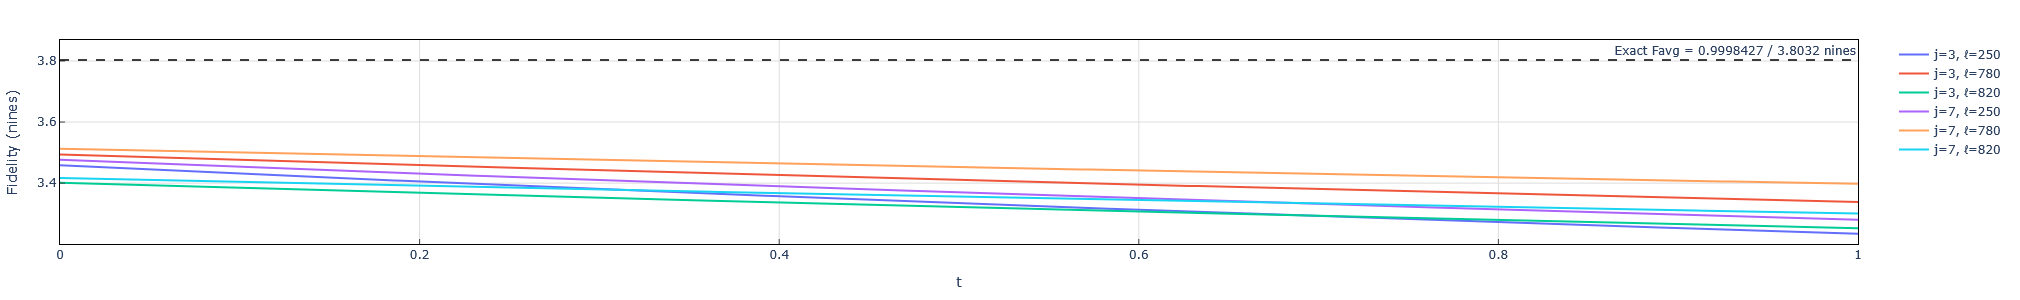

Samples for j=7, ℓ=780, i=0


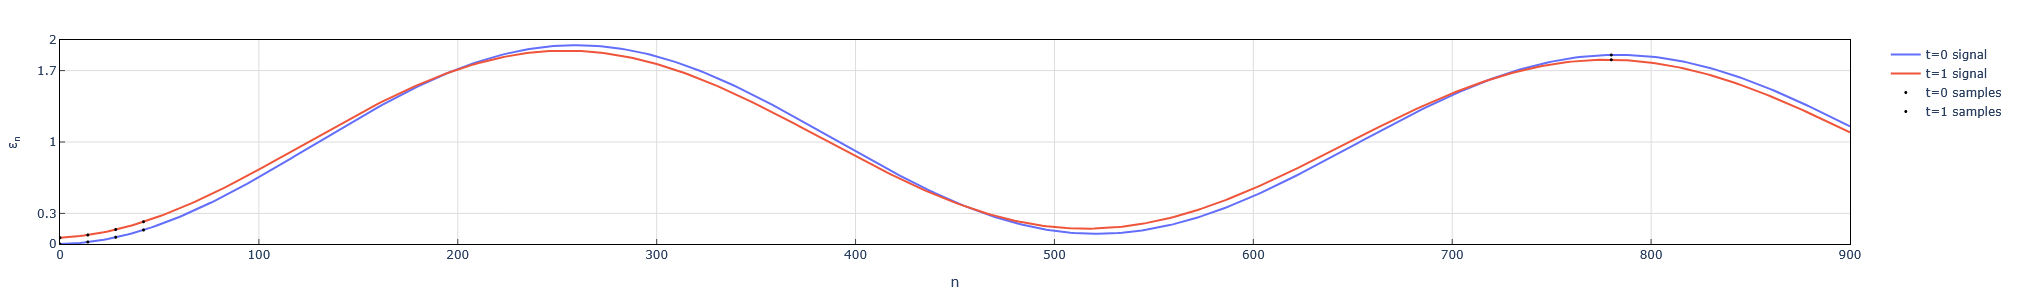

In [3]:
run_scenario(
    noise_dephasing(0.0004) @ noise_overrotation(0.012) @ T_sqrtX,
    lambda t: get_Schur_gauge_state(0.02 * pi * t, -pi/2, 0.01 * t),
    lambda t: get_Schur_gauge_measurement(0.02 * t, 0.028 * t),
    [(3, 250), (3, 780), (3, 820), (7, 250), (7, 780), (7, 820)],
    900, (7, 780)
)

### Amplitude damping noise

Exact F_avg in Schur gauge: 0.9998833335 = 3.9331 nines


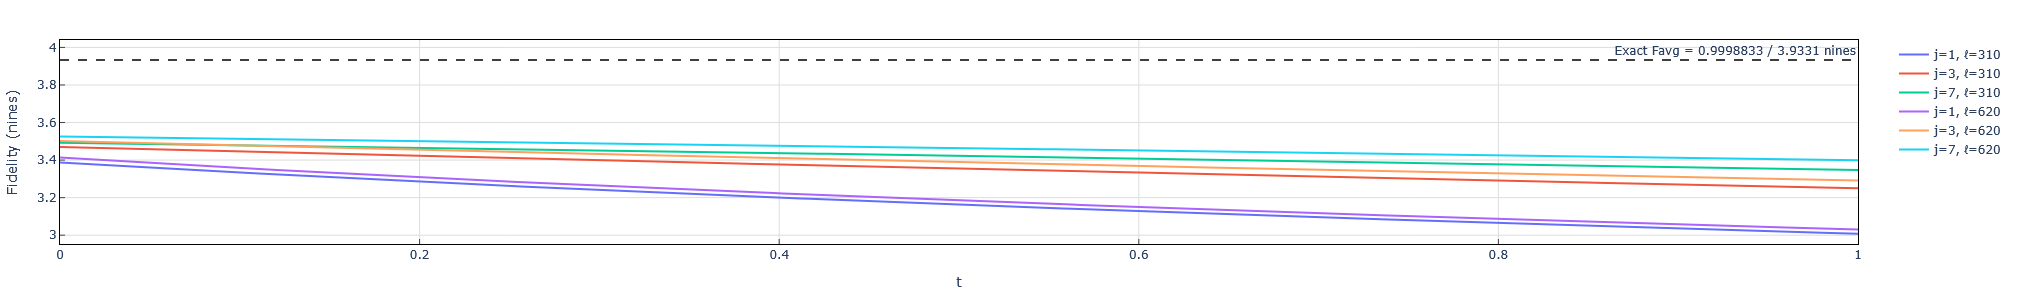

Samples for j=1, ℓ=620, i=0


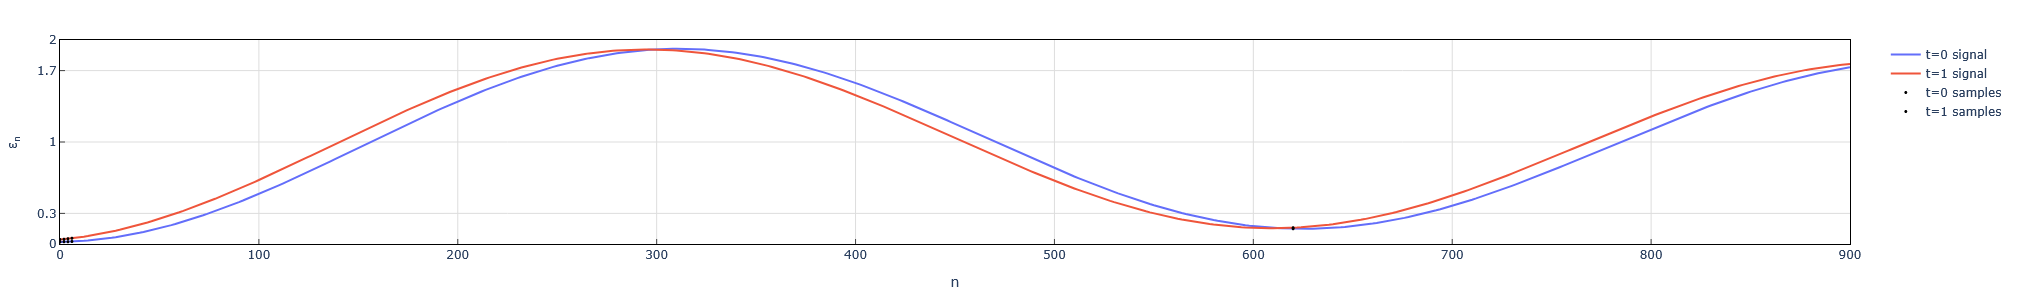

In [4]:
run_scenario(
    noise_amplitude_damping(0.0003) @ noise_overrotation(0.01) @ T_sqrtX,
    lambda t: get_Schur_gauge_state(0.05 * pi * t, -pi/2, 0.01 * t),
    lambda t: get_Schur_gauge_measurement(0.01, 0.01),
    [(1, 310), (3, 310), (7, 310), (1, 620), (3, 620), (7, 620)],
    900, (1, 620)
)

### Choice to $j$ and $\ell$

The 3D plot below shows changes in the lower bound obtained by sweeping over $j$ and $\ell$ for a given channel noise and SPAM error model.
The $\varepsilon_n$ curve below acts as reference for which values of $j$, $\ell$ and $i$ a bound can be computed.

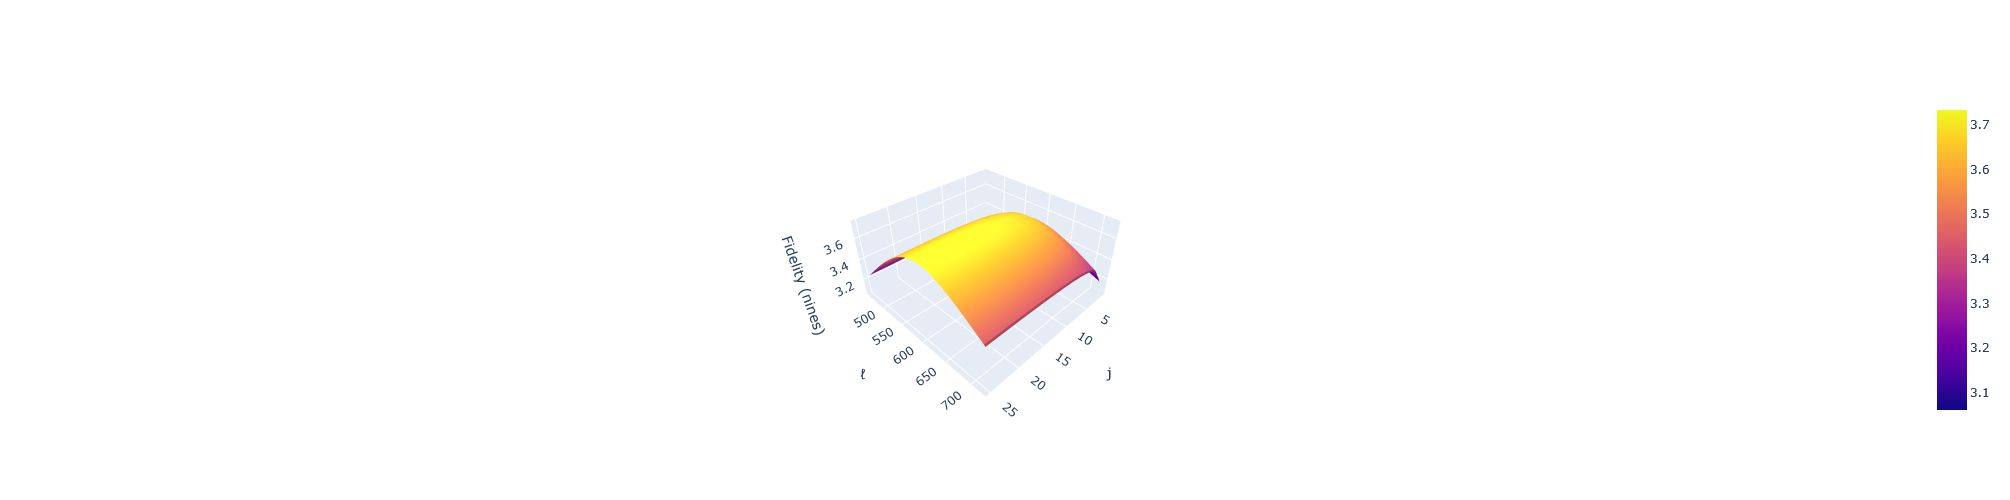

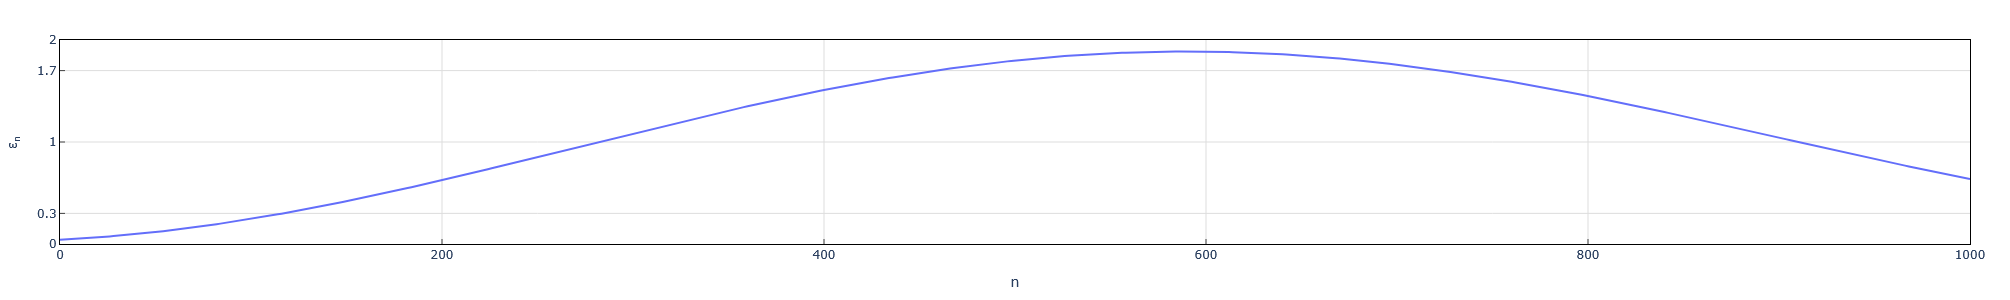

In [5]:
T = noise_dephasing(0.0003) @ noise_overrotation(0.005) @ T_sqrtX
state = get_Schur_gauge_state(0.05*pi, -pi/2, 0.01)
measurement = get_Schur_gauge_measurement(0.01, 0.01)

SchurT = canonical_Schur_PTM(T)

data = [
    ( j, ell, nines(get_simulated_SPAM_bound(SchurT, state, measurement, j, ell)) )
    for j in range(1, 25+1, 2)
    for ell in range(400, 800, 10)
]

x_coords = sorted(list(set(pt[0] for pt in data)))
y_coords = sorted(list(set(pt[1] for pt in data)))
z_matrix = [[0.0 for _ in range(len(x_coords))] for _ in range(len(y_coords))]
x_map = {val: idx for idx, val in enumerate(x_coords)}
y_map = {val: idx for idx, val in enumerate(y_coords)}
for x, y, z in data:
    z_matrix[y_map[y]][x_map[x]] = z

fig = go.Figure(data=[go.Surface(x=x_coords, y=y_coords, z=z_matrix)])
fig.update_layout(
    width=700, height=500,
    scene=dict(
        aspectmode='manual', aspectratio=dict(x=1, y=1, z=0.5),
        xaxis_title='j', yaxis_title='ℓ', zaxis_title='Fidelity (nines)'
    ),
)
fig.show()

plot_epsilon_signal(SchurT, [("",state,measurement)], 1000)

### Choice of $i$ offset

The short-sequence condition $\sqrt{\varepsilon_{0}} + \sqrt{\varepsilon_{2}} \le \frac{1}{2}$ is required to guarantee the channel's Pauli transfer matrix is diagonalizable with eigenvalues $\{ 1, \lambda_0, \lambda_1, \lambda_1^* \}$.

Under certain conditions, such as extreme in-plane overrotation of the initial state, an additional offset $i$ is required to compensate for the phase in the oscillating $\varepsilon_n$ signal.

In this case, the condition becomes $\sqrt{\varepsilon_{i}} + \sqrt{\varepsilon_{i+2}} \le \frac{1}{2}$, and $i$ is ideally chosen at the earliest minimum in the $\varepsilon_n$ signal.

Exact F_avg in Schur gauge: 0.9999625002 = 4.4260 nines


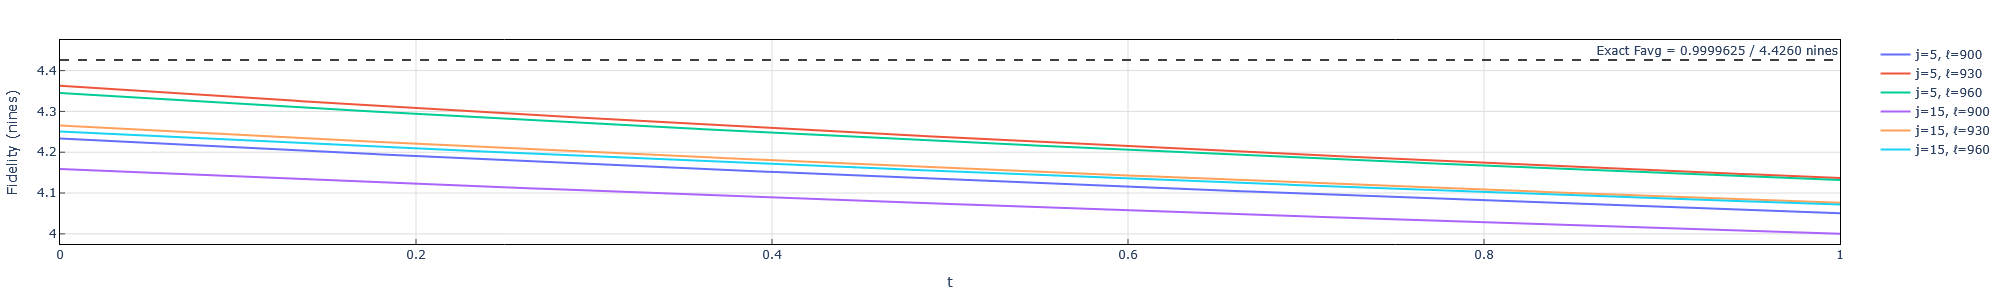

Samples for j=5, ℓ=930, i=300


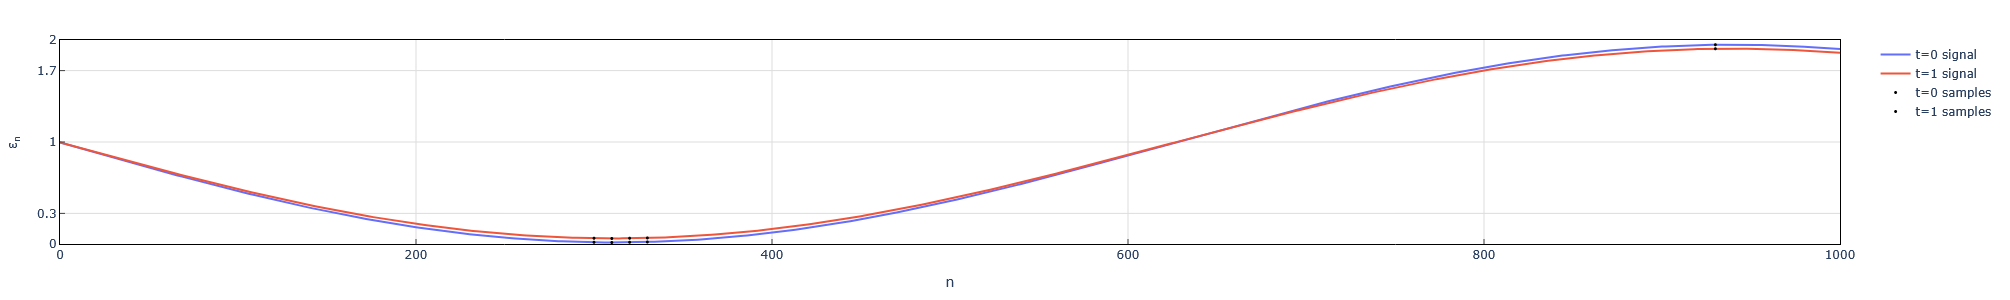

In [6]:
run_scenario(
    noise_dephasing(0.0001) @ noise_overrotation(0.005) @ T_sqrtX,
    lambda t: get_Schur_gauge_state(0.5*pi, pi/2, 0.0),
    lambda t: get_Schur_gauge_measurement(0.02*t, 0.02*t),
    [(5, 900), (5, 930), (5, 960), (15, 900), (15, 930), (15, 960)],
    1000, (5, 930),
    i=300
)

### State preparation off-plane sensitivity

The ideal choices of $\ell$ occur when $|1 - \varepsilon_\ell|$ is a local maximum satisfying $|1 - \varepsilon_\ell| \ge 7/10$. Thus, for a fixed choice of $j$ and $\ell$, our protocol is sensitive to state preparation errors with the state off the gate's rotation plane. Such errors induce a phase offset to the oscillatory part of the $\varepsilon_n$ signal, which shifts the optimal location for $|1 - \varepsilon_\ell|$ slightly. In most cases, this leads to a modest change in the fidelity lower bound.

Here, this is illustrated by having a simple model with some dephasing and coherent overrotation noise, ideal measurements, and a state parameterized by $\alpha = 0.05 \pi$, $\beta = \frac{\pi}{2} (2t - 1)$ and $\gamma = 0$, corresponding to a rotation around the (Schur gauge) z-axis from $-\pi/2$ to $+\pi/2$. The certified fidelity lower bound achieves its minimum and maximum value near $\beta = \pm \pi/2$, corresponding to an off-axis rotation.

In [7]:
run_scenario(
    noise_dephasing(0.0004) @ noise_overrotation(0.01) @ T_sqrtX,
    lambda t: get_Schur_gauge_state(0.05 * pi, pi/2 * (2*t - 1), 0),
    lambda t: get_Schur_gauge_measurement(0.0, 0.0),
    [(11, 260), (11, 280), (11, 300), (11, 320), (11, 340)],
    1000, (11, 300)
)

Exact F_avg in Schur gauge: 0.9998500035 = 3.8239 nines


Samples for j=11, ℓ=300, i=0
